# Training Script with Cross-Validation & Hyperparameter Tuning

This notebook trains the custom `Regression` model from `scaffold.py`, performs **$K$-fold Cross-Validation** and **Grid Search Hyperparameter Tuning** over:
- Polynomial Degree (`max_dim` $\in \{1, 2, 3, 4\}$)
- Ridge Regularization Strength ($\lambda \in [10^{-5}, 10^3]$)

It evaluates both standard shuffled $K$-Fold CV and sequential/block CV (to guard against data drift discovered in `data_analysis.ipynb`), and finally evaluates the optimal model on unseen test data.

In [1]:
# DO NOT REMOVE THESE
# These two lines make sure any changes you make in scaffold.py
# are automatically reloaded each time you run a cell in this notebook.
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold

# Import Regression class from scaffold.py
from scaffold import Regression

In [3]:
# Load the training dataset
data = pd.read_csv('data_train.csv')
features = [col for col in data.columns if col != 'y']

# Hold out 20% for final, untouched test evaluation
# You can choose shuffle=True or shuffle=False depending on validation strategy
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42, shuffle=True)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print(f"Features ({len(features)}): {features}")
print(f"Train data shape: {train_data.shape}")
print(f"Test data shape:  {test_data.shape}")

Features (7): ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7']
Train data shape: (8000, 8)
Test data shape:  (2000, 8)


## 1. Cross-Validation Implementation

We implement a modular cross-validation function that:
1. Splits the training data into $K$ folds.
2. Fits the `Regression` model on $K-1$ folds.
3. Evaluates MSE on the held-out validation fold and the training folds.
4. Returns the mean and standard deviation of Train and Validation MSE across all $K$ folds.

In [4]:
def cross_val_score_regression(X, y, max_dim, lmbda, stepsize=1, n_splits=5, shuffle=True, random_state=42):
    """
    Performs K-Fold cross-validation for a specific (max_dim, lmbda) combination.
    
    Parameters:
        X: numpy array or DataFrame of shape (n_samples, n_features)
        y: numpy array or Series of shape (n_samples,)
        max_dim: maximum polynomial power
        lmbda: L2 ridge regularization penalty
        stepsize: power step size (default=1)
        n_splits: number of CV folds (default=5)
        shuffle: whether to shuffle before splitting
        random_state: random seed for reproducibility
        
    Returns:
        mean_val_mse, std_val_mse, mean_train_mse, std_train_mse
    """
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y, dtype=float).ravel()
    
    kf = KFold(n_splits=n_splits, shuffle=shuffle, random_state=random_state if shuffle else None)
    
    train_mses = []
    val_mses = []
    
    for train_idx, val_idx in kf.split(X_arr):
        X_tr, y_tr = X_arr[train_idx], y_arr[train_idx]
        X_va, y_va = X_arr[val_idx], y_arr[val_idx]
        
        # Instantiate and fit model on training folds
        model = Regression(max_dim=max_dim, lmbda=lmbda, stepsize=stepsize)
        model.fit(X_tr, y_tr)
        
        # Predict on training folds and validation fold
        pred_tr = model.predict(X_tr)
        pred_va = model.predict(X_va)
        
        train_mses.append(np.mean((pred_tr - y_tr) ** 2))
        val_mses.append(np.mean((pred_va - y_va) ** 2))
        
    return np.mean(val_mses), np.std(val_mses), np.mean(train_mses), np.std(train_mses)

## 2. Grid Search Hyperparameter Tuning

We perform a systematic grid search over:
- `max_dim`: polynomial degrees $[1, 2, 3, 4]$
- `lmbda`: $\lambda \in [10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0, 1000.0]$

In [5]:
# Define hyperparameter grid
max_dim_grid = [1, 2, 3, 4]
lmbda_grid = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0, 1000.0]

X_train_vals = train_data[features].values
y_train_vals = train_data['y'].values

results = []

print(f"Running 5-Fold Cross-Validation across {len(max_dim_grid) * len(lmbda_grid)} hyperparameter combinations...")
for dim in max_dim_grid:
    for lmbda in lmbda_grid:
        val_mean, val_std, tr_mean, tr_std = cross_val_score_regression(
            X_train_vals, y_train_vals,
            max_dim=dim,
            lmbda=lmbda,
            n_splits=5,
            shuffle=True,
            random_state=42
        )
        results.append({
            'max_dim': dim,
            'lmbda': lmbda,
            'val_mse_mean': val_mean,
            'val_mse_std': val_std,
            'train_mse_mean': tr_mean,
            'train_mse_std': tr_std
        })

df_results = pd.DataFrame(results)

# Sort by lowest validation MSE
df_sorted = df_results.sort_values(by='val_mse_mean').reset_index(drop=True)
best_config = df_sorted.iloc[0]

print("\n--- TOP 10 BEST HYPERPARAMETER CONFIGURATIONS ---")
print(df_sorted.head(10).to_string(index=False))

print(f"\nOptimal Hyperparameters:")
print(f"  Best max_dim: {int(best_config['max_dim'])}")
print(f"  Best lmbda:   {best_config['lmbda']}")
print(f"  Best CV Validation MSE: {best_config['val_mse_mean']:.4f} (+/- {best_config['val_mse_std']:.4f})")

Running 5-Fold Cross-Validation across 48 hyperparameter combinations...

--- TOP 10 BEST HYPERPARAMETER CONFIGURATIONS ---
 max_dim   lmbda  val_mse_mean  val_mse_std  train_mse_mean  train_mse_std
       4 0.01000     52.770889     1.831651       52.372568       0.459514
       4 0.00100     52.771010     1.835647       52.372344       0.459560
       4 0.00010     52.771043     1.836075       52.372342       0.459561
       4 0.00001     52.771047     1.836119       52.372342       0.459561
       4 0.10000     52.778955     1.807703       52.383333       0.457707
       4 1.00000     52.980761     1.765517       52.596953       0.446882
       4 5.00000     53.976878     1.823281       53.600683       0.433731
       3 0.00001     54.161535     1.962850       53.891476       0.494137
       3 0.00010     54.161537     1.962835       53.891476       0.494136
       3 0.00100     54.161551     1.962691       53.891478       0.494136

Optimal Hyperparameters:
  Best max_dim: 4
  Best 

## 3. Visualizing Hyperparameter Performance

We plot Validation MSE against regularization strength $\lambda$ across the polynomial degrees to visualize the bias-variance trade-off.

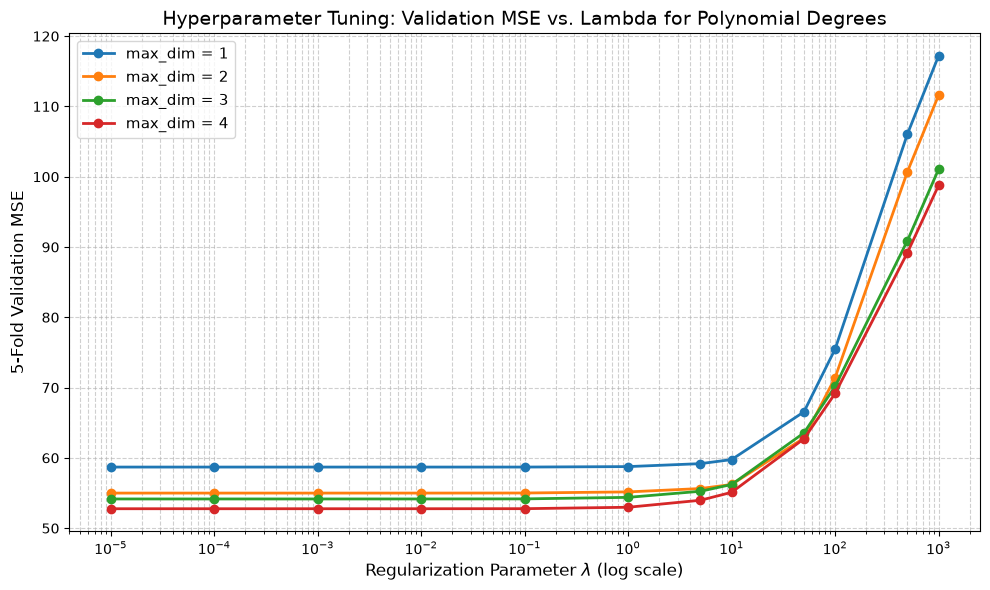

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

for dim in max_dim_grid:
    subset = df_results[df_results['max_dim'] == dim]
    ax.plot(
        subset['lmbda'],
        subset['val_mse_mean'],
        marker='o',
        linewidth=2,
        label=f"max_dim = {dim}"
    )

ax.set_xscale('log')
ax.set_xlabel(r"Regularization Parameter $\lambda$ (log scale)", fontsize=12)
ax.set_ylabel("5-Fold Validation MSE", fontsize=12)
ax.set_title("Hyperparameter Tuning: Validation MSE vs. Lambda for Polynomial Degrees", fontsize=14)
ax.grid(True, which="both", ls="--", alpha=0.6)
ax.legend(fontsize=11)

# Cap y-axis if high-degree polynomials explode at small lambda
current_ylim = ax.get_ylim()
if current_ylim[1] > 200:
    ax.set_ylim(45, 120)

plt.tight_layout()
plt.show()

## 4. Sequential / Block Cross-Validation (Testing Against Data Drift)

Section 6 of `data_analysis.ipynb` revealed strong correlation between row index and feature values (data drift).
We now run non-shuffled / block cross-validation (`shuffle=False`) to see which model extrapolates best across sequential blocks.

In [7]:
block_results = []

for dim in [1, 2, 3]:
    for lmbda in [1e-3, 1e-2, 0.1, 1.0, 10.0, 50.0, 100.0]:
        val_mean, val_std, tr_mean, tr_std = cross_val_score_regression(
            X_train_vals, y_train_vals,
            max_dim=dim,
            lmbda=lmbda,
            n_splits=5,
            shuffle=False  # Sequential / non-shuffled folds
        )
        block_results.append({
            'max_dim': dim,
            'lmbda': lmbda,
            'val_mse_mean': val_mean,
            'val_mse_std': val_std
        })

df_block = pd.DataFrame(block_results).sort_values(by='val_mse_mean').reset_index(drop=True)
print("--- TOP 5 CONFIGURATIONS ON SEQUENTIAL / BLOCK CV ---")
print(df_block.head(5).to_string(index=False))

--- TOP 5 CONFIGURATIONS ON SEQUENTIAL / BLOCK CV ---
 max_dim  lmbda  val_mse_mean  val_mse_std
       3  0.010     54.261247     1.338479
       3  0.001     54.261344     1.338491
       3  0.100     54.268938     1.337677
       3  1.000     54.475421     1.331285
       2  0.001     55.017295     1.272044


## 5. Final Model Training & Holdout Test Evaluation

We train the optimal model selected by cross-validation on the complete training set and evaluate its true generalization performance on the untouched holdout `test_data`.

--- FINAL MODEL EVALUATION (max_dim=4, lmbda=0.01) ---
Training MSE:     52.4119
Holdout Test MSE: 50.9323


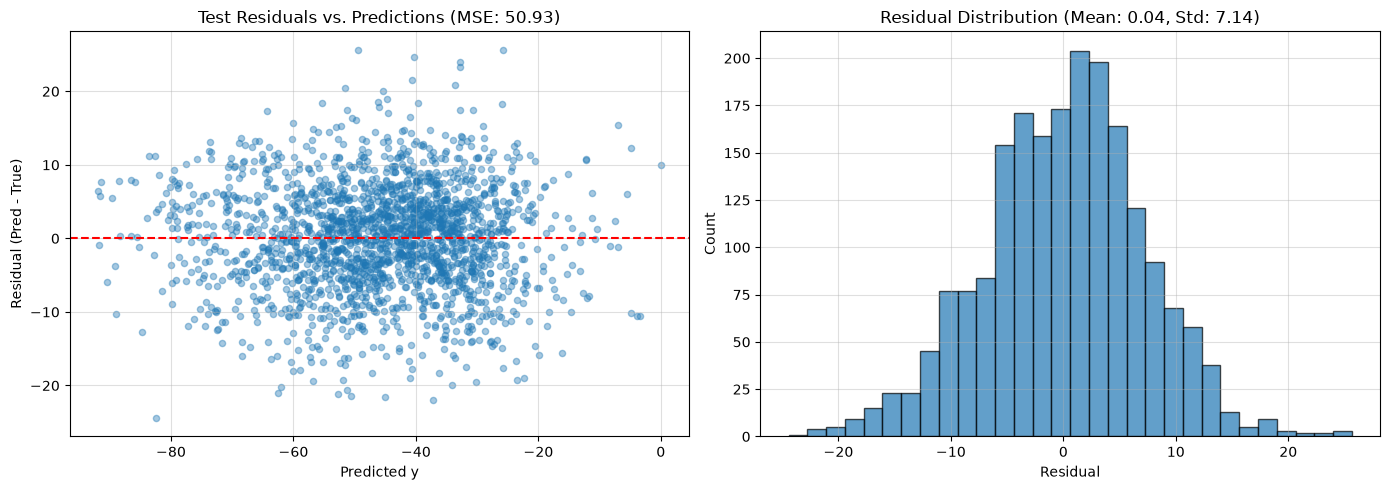

In [8]:
best_max_dim = int(best_config['max_dim'])
best_lmbda = float(best_config['lmbda'])

# Fit optimal model on full train_data
best_model = Regression(max_dim=best_max_dim, lmbda=best_lmbda)
best_model.fit(train_data[features], train_data['y'])

# Predict on training and test sets
train_pred = best_model.predict(train_data[features])
test_pred = best_model.predict(test_data[features])

train_mse = np.mean((train_pred - train_data['y'].values) ** 2)
test_mse = np.mean((test_pred - test_data['y'].values) ** 2)

print(f"--- FINAL MODEL EVALUATION (max_dim={best_max_dim}, lmbda={best_lmbda}) ---")
print(f"Training MSE:     {train_mse:.4f}")
print(f"Holdout Test MSE: {test_mse:.4f}")

# Residual analysis on test set
residuals = test_pred - test_data['y'].values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_pred, residuals, alpha=0.4, color='tab:blue', s=20)
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title(f"Test Residuals vs. Predictions (MSE: {test_mse:.2f})")
axes[0].set_xlabel("Predicted y")
axes[0].set_ylabel("Residual (Pred - True)")
axes[0].grid(True, alpha=0.4)

axes[1].hist(residuals, bins=30, color='tab:blue', edgecolor='black', alpha=0.7)
axes[1].set_title(f"Residual Distribution (Mean: {np.mean(residuals):.2f}, Std: {np.std(residuals):.2f})")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Count")
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

## 6. Updating scaffold.py Defaults for Online Submission

To submit your best model to the online benchmark, ensure `scaffold.py` uses the optimal hyperparameters as defaults in `Regression.__init__`.

In [9]:
print(f"Recommended default parameters for scaffold.py:")
print(f"class Regression:")
print(f"    def __init__(self, stepsize=1, max_dim={best_max_dim}, lmbda={best_lmbda}):")

Recommended default parameters for scaffold.py:
class Regression:
    def __init__(self, stepsize=1, max_dim=4, lmbda=0.01):
